# 🎨 Práctica de Seaborn: EDA visual de pedidos de delivery
**Dataset:** `delivery_pedidos.csv` · 400 pedidos · 11 columnas (datos **sintéticos**, ya limpios).
**Objetivo:** practicar las herramientas estadísticas de Seaborn (distribuciones, comparaciones, relaciones y vista multivariada) y combinarlas con Matplotlib.

**Cómo trabajar:** ejecutá cada *demo*, hacé los ejercicios ✏️ y respondé las preguntas con tus palabras. Todo gráfico necesita **título, ejes con unidades y, si hay varios grupos, leyenda**.

> En Google Colab: subí `delivery_pedidos.csv` desde el panel de archivos (📁) antes de ejecutar.

### Diccionario de datos
| Columna | Descripción |
|---|---|
| `zona` | Zona de la ciudad: Centro, Norte, Sur, Costa |
| `tipo_comida` | Pizza, Hamburguesa, Sushi, Vegano |
| `franja` | Almuerzo, Merienda, Cena |
| `tipo_dia` | Semana / Fin de semana |
| `lluvia` | ¿Llovía al momento del pedido? (Sí / No) |
| `distancia_km` | Distancia del local al cliente (km) |
| `tiempo_entrega_min` | Minutos desde el pedido hasta la entrega |
| `monto` | Importe del pedido ($) |
| `propina` | Propina ($); 0 si no dejó |
| `calificacion` | Puntaje del cliente (1 a 5) |

### Mapa de funciones
| ¿Qué quiero saber? | Funciones |
|---|---|
| ¿Cómo se distribuye una variable? | `histplot`, `kdeplot`, `displot` |
| ¿Cómo comparo categorías? | `boxplot`, `violinplot`, `stripplot`, `barplot`, `countplot` |
| ¿Cómo se relacionan dos numéricas? | `scatterplot`, `regplot`, `lmplot` |
| ¿Qué pasa con muchas variables a la vez? | `heatmap` (correlación), `pairplot` |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='deep', font_scale=1.05)   # un solo estilo para todo el notebook

df = pd.read_csv('delivery_pedidos.csv')
print(df.shape)
df.head()

(400, 11)


,id_pedido,zona,tipo_comida,franja,tipo_dia,lluvia,distancia_km,tiempo_entrega_min,monto,propina,calificacion
0,D-0001,Costa,Pizza,Cena,Fin de semana,No,2.2,63,6700,0,3
1,D-0002,Costa,Hamburguesa,Cena,Semana,No,3.4,28,12400,0,5
2,D-0003,Norte,Pizza,Merienda,Semana,No,0.9,10,10600,800,5
3,D-0004,Centro,Hamburguesa,Almuerzo,Fin de semana,No,7.5,54,10700,0,4
4,D-0005,Centro,Pizza,Merienda,Semana,Sí,2.0,34,11800,700,5


In [2]:
df.info()
df.describe().round(1)

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           400 non-null    str    
 1   zona                400 non-null    str    
 2   tipo_comida         400 non-null    str    
 3   franja              400 non-null    str    
 4   tipo_dia            400 non-null    str    
 5   lluvia              400 non-null    str    
 6   distancia_km        400 non-null    float64
 7   tiempo_entrega_min  400 non-null    int64  
 8   monto               400 non-null    int64  
 9   propina             400 non-null    int64  
 10  calificacion        400 non-null    int64  
dtypes: float64(1), int64(4), str(6)
memory usage: 34.5 KB


,distancia_km,tiempo_entrega_min,monto,propina,calificacion
count,400.0,400.0,400.0,400.0,400.0
mean,2.9,30.7,10813.0,660.0,4.7
std,1.9,11.1,4429.1,570.1,0.6
min,0.3,10.0,3500.0,0.0,2.0
25%,1.5,23.0,7600.0,0.0,4.0
50%,2.6,29.0,9850.0,700.0,5.0
75%,3.9,36.0,12900.0,1000.0,5.0
max,10.6,77.0,33200.0,3200.0,5.0


---
## 1️⃣ Distribuciones
`histplot` con `kde=True` muestra la forma de una variable. Primero, **la distribución del tiempo de entrega**:

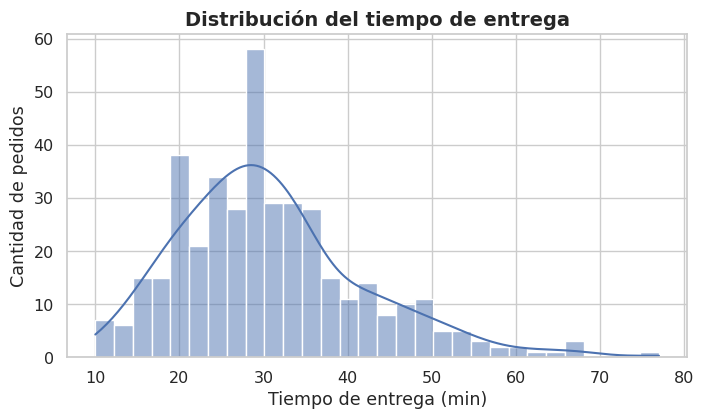

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.histplot(data=df, x='tiempo_entrega_min', bins=30, kde=True, ax=ax)
ax.set_title('Distribución del tiempo de entrega', fontsize=14, fontweight='bold')
ax.set_xlabel('Tiempo de entrega (min)')
ax.set_ylabel('Cantidad de pedidos')
plt.show()

### ✏️ Ejercicio 1.1
Hacé lo mismo con **`monto`**. Agregá una línea vertical para la **mediana** y otra para la **media** (`ax.axvline`) con leyenda.
**Pregunta:** ¿la distribución es simétrica o sesgada? ¿Qué medida representa mejor el pedido típico?

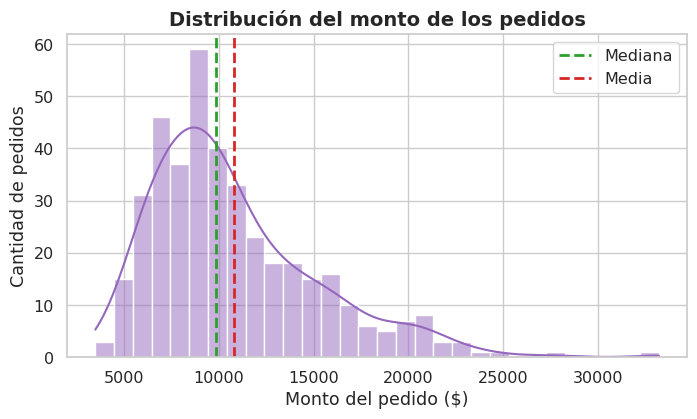

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.histplot(data=df, x='monto', bins=30, kde=True, color='tab:purple', ax=ax)
ax.axvline(df['monto'].median(), color='tab:green', linestyle='--', linewidth=2, label='Mediana')
ax.axvline(df['monto'].mean(), color='tab:red', linestyle='--', linewidth=2, label='Media')
ax.set_title('Distribución del monto de los pedidos', fontsize=14, fontweight='bold')
ax.set_xlabel('Monto del pedido ($)')
ax.set_ylabel('Cantidad de pedidos')
ax.legend()
plt.show()

**Respuesta modelo:** está **sesgada a la derecha**: la media ($10.813) supera a la mediana ($9.850) por unos pocos pedidos grandes. La mediana representa mejor el pedido típico.

### ✏️ Ejercicio 1.2
Compará la distribución de `tiempo_entrega_min` **con y sin lluvia** usando `kdeplot` con `hue='lluvia'`, `fill=True` y `common_norm=False`.
**Pregunta:** ¿qué le pasa al tiempo cuando llueve?

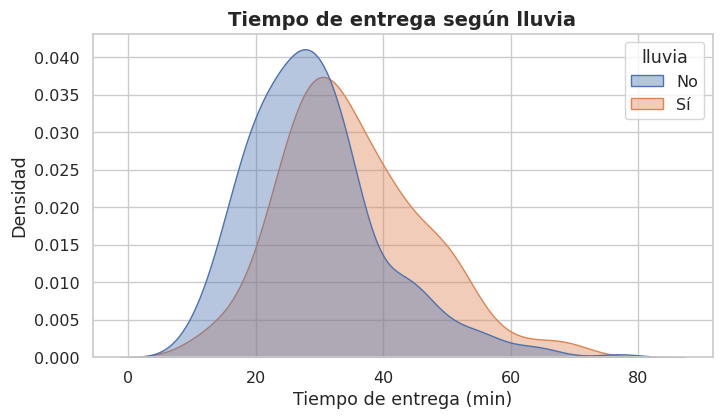

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.kdeplot(data=df, x='tiempo_entrega_min', hue='lluvia', fill=True, common_norm=False, alpha=0.4, ax=ax)
ax.set_title('Tiempo de entrega según lluvia', fontsize=14, fontweight='bold')
ax.set_xlabel('Tiempo de entrega (min)')
ax.set_ylabel('Densidad')
plt.show()

**Respuesta modelo:** con lluvia la curva se **desplaza hacia la derecha**: la mediana pasa de 28 a 33 min (≈ +5 min). Además hay una cola larga de pedidos muy demorados (outliers) en ambos grupos.

---
## 2️⃣ Comparar categorías
`boxplot` resume mediana, cuartiles y outliers por grupo. Demo: **tiempo según franja horaria**.

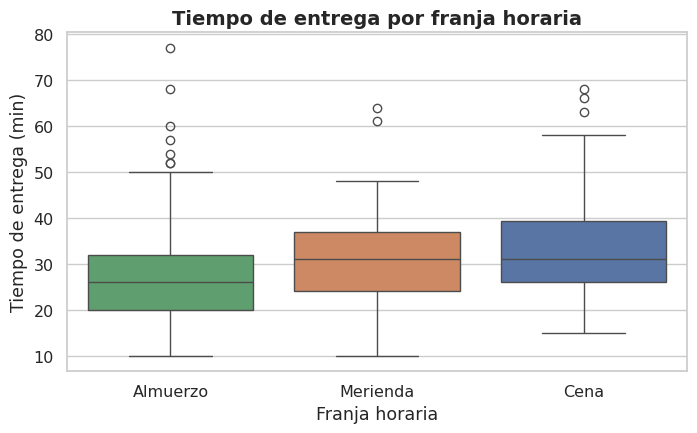

In [6]:
orden = ['Almuerzo', 'Merienda', 'Cena']
fig, ax = plt.subplots(figsize=(8, 4.4))
sns.boxplot(data=df, x='franja', y='tiempo_entrega_min', order=orden, hue='franja', legend=False, ax=ax)
ax.set_title('Tiempo de entrega por franja horaria', fontsize=14, fontweight='bold')
ax.set_xlabel('Franja horaria')
ax.set_ylabel('Tiempo de entrega (min)')
plt.show()

### ✏️ Ejercicio 2.1
Con `violinplot`, graficá `monto` por `tipo_comida`, **ordenado por mediana** (de mayor a menor). Usá `inner='quartile'` y `cut=0`.
**Pregunta:** ¿qué tipo de comida tiene el pedido más caro? ¿Cuál tiene más dispersión?

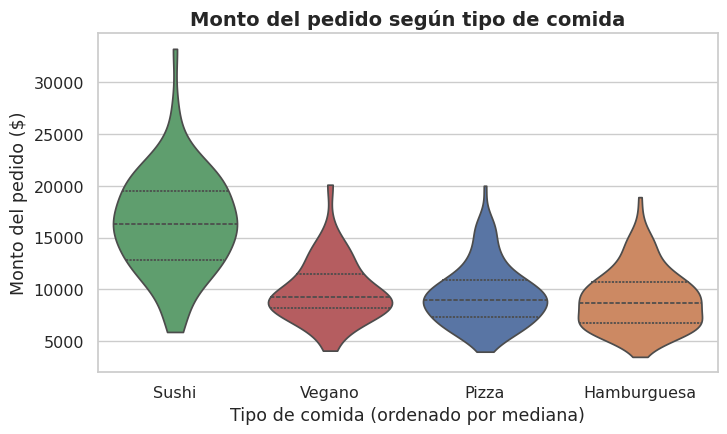

In [7]:
orden = df.groupby('tipo_comida')['monto'].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 4.4))
sns.violinplot(data=df, x='tipo_comida', y='monto', order=orden, hue='tipo_comida', legend=False, inner='quartile', cut=0, ax=ax)
ax.set_title('Monto del pedido según tipo de comida', fontsize=14, fontweight='bold')
ax.set_xlabel('Tipo de comida (ordenado por mediana)')
ax.set_ylabel('Monto del pedido ($)')
plt.show()

**Respuesta modelo:** el **Sushi** tiene el pedido mediano más caro ($16.300) y también la mayor dispersión; Hamburguesa es el más barato ($8.700).

### ✏️ Ejercicio 2.2
Graficá `tiempo_entrega_min` por `zona` con un `boxplot` y **superponé un `stripplot`** (puntos chicos, `color='black'`, `alpha=0.3`, `size=3`) para ver los datos reales.
**Pregunta:** ¿hay zonas más lentas? ¿Qué ves en los outliers?

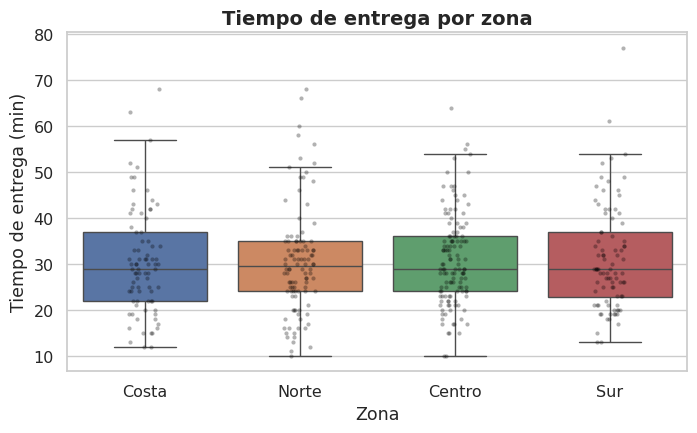

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.4))
sns.boxplot(data=df, x='zona', y='tiempo_entrega_min', hue='zona', legend=False, showfliers=False, ax=ax)
sns.stripplot(data=df, x='zona', y='tiempo_entrega_min', color='black', alpha=0.3, size=3, ax=ax)
ax.set_title('Tiempo de entrega por zona', fontsize=14, fontweight='bold')
ax.set_xlabel('Zona')
ax.set_ylabel('Tiempo de entrega (min)')
plt.show()

**Respuesta modelo:** las zonas tienen medianas parecidas: la zona **no** parece ser el factor principal. Hay **12 pedidos atípicos** (más de 56 min) repartidos en todas las zonas, probablemente incidentes puntuales.

### ✏️ Ejercicio 2.3
Con `countplot`, mostrá **cuántos pedidos hay por `tipo_comida`**, ordenado de mayor a menor, y escribí el número sobre cada barra con `ax.bar_label(ax.containers[0])`.

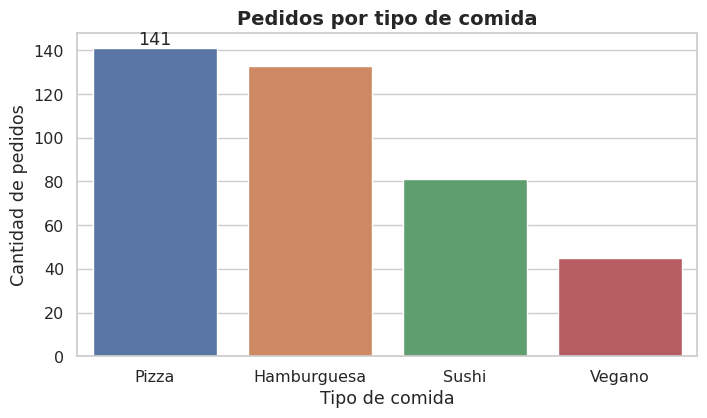

In [9]:
orden = df['tipo_comida'].value_counts().index
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.countplot(data=df, x='tipo_comida', order=orden, hue='tipo_comida', legend=False, ax=ax)
ax.bar_label(ax.containers[0])
ax.set_title('Pedidos por tipo de comida', fontsize=14, fontweight='bold')
ax.set_xlabel('Tipo de comida')
ax.set_ylabel('Cantidad de pedidos')
plt.show()

**Respuesta modelo:** la Pizza es lo más pedido (141 pedidos) y Vegano lo menos pedido (45).

---
## 3️⃣ Relaciones entre dos variables numéricas
Demo: **¿más distancia, más tiempo?** Coloreamos por lluvia con `hue`.

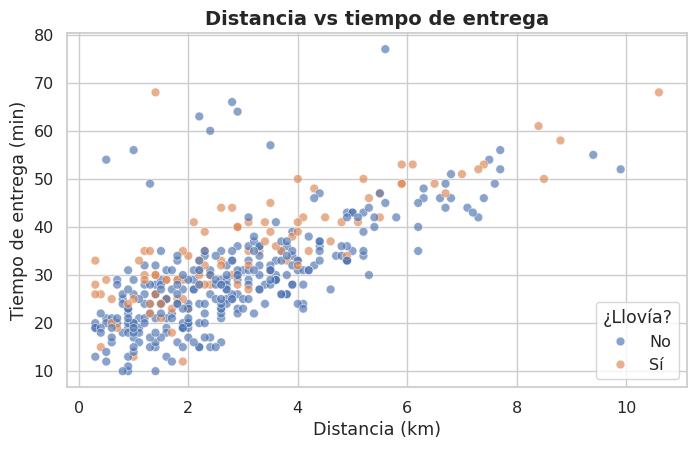

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.6))
sns.scatterplot(data=df, x='distancia_km', y='tiempo_entrega_min', hue='lluvia', alpha=0.65, s=40, ax=ax)
ax.set_title('Distancia vs tiempo de entrega', fontsize=14, fontweight='bold')
ax.set_xlabel('Distancia (km)')
ax.set_ylabel('Tiempo de entrega (min)')
ax.legend(title='¿Llovía?')
plt.show()

### ✏️ Ejercicio 3.1
Con **`sns.lmplot`** agregá la **línea de regresión** por grupo (`hue='lluvia'`, `height=4.5`, `aspect=1.4`).
**Pregunta:** ¿las líneas son paralelas? ¿Cuánto tiempo suma cada km extra?

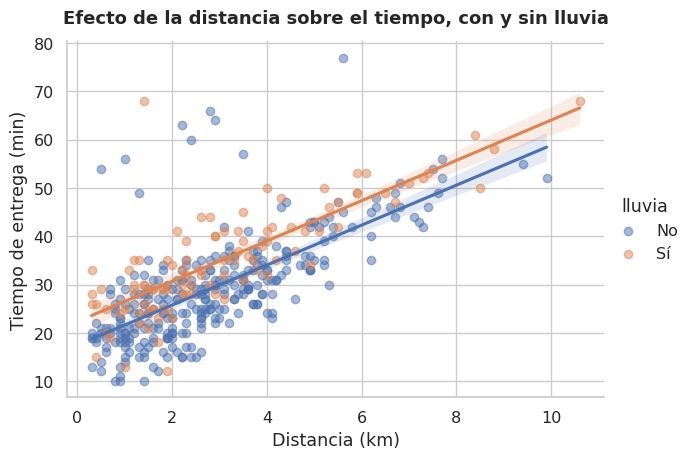

In [11]:
g = sns.lmplot(data=df, x='distancia_km', y='tiempo_entrega_min', hue='lluvia', height=4.5, aspect=1.4, scatter_kws={'alpha': 0.5})
g.set_axis_labels('Distancia (km)', 'Tiempo de entrega (min)')
g.figure.suptitle('Efecto de la distancia sobre el tiempo, con y sin lluvia', fontsize=13, fontweight='bold', y=1.02)
plt.show()

**Respuesta modelo:** las rectas son **casi paralelas** (pendiente ≈ 4,1 min/km sin lluvia y 4,2 con lluvia): cada km suma unos 4 minutos, y la lluvia agrega un tiempo fijo, más o menos constante, sin cambiar el ritmo por km. Correlación distancia–tiempo: r = 0,71.

### ✏️ Ejercicio 3.2
Graficá `monto` (X) vs `propina` (Y) con `scatterplot`, coloreando por `tipo_comida`.
**Pregunta:** ¿qué patrón raro aparece en la propina? ¿Qué implica para una correlación?

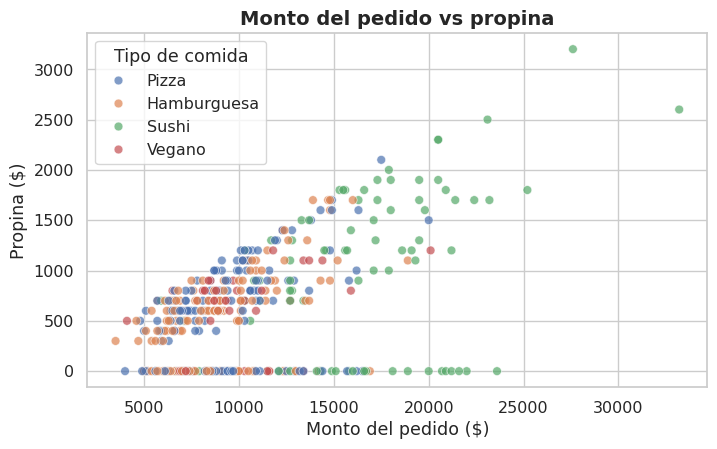

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.6))
sns.scatterplot(data=df, x='monto', y='propina', hue='tipo_comida', alpha=0.7, s=40, ax=ax)
ax.set_title('Monto del pedido vs propina', fontsize=14, fontweight='bold')
ax.set_xlabel('Monto del pedido ($)')
ax.set_ylabel('Propina ($)')
ax.legend(title='Tipo de comida')
plt.show()

**Respuesta modelo:** el 29 % de los pedidos tiene **propina = 0**, lo que forma una línea horizontal pegada al eje. Entre quienes sí dejan propina, esta crece con el monto. Como hay tantos ceros, una correlación lineal simple subestima la relación (r = 0,51).

---
## 4️⃣ Vista multivariada
Demo: **heatmap de correlación** de las variables numéricas.

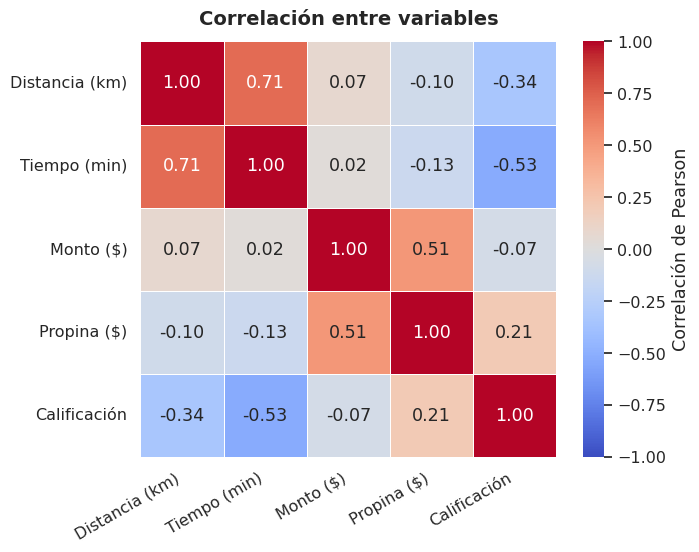

In [13]:
cols = {'distancia_km': 'Distancia (km)', 'tiempo_entrega_min': 'Tiempo (min)', 'monto': 'Monto ($)', 'propina': 'Propina ($)', 'calificacion': 'Calificación'}
corr = df[list(cols)].corr().rename(index=cols, columns=cols)
fig, ax = plt.subplots(figsize=(7, 5.4))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={'label': 'Correlación de Pearson'}, ax=ax)
ax.set_title('Correlación entre variables', fontsize=14, fontweight='bold', pad=12)
plt.xticks(rotation=30, ha='right')
plt.show()

### ✏️ Ejercicio 4.1
Armá un **`pairplot`** de `distancia_km`, `tiempo_entrega_min`, `monto` y `calificacion`, coloreado por `lluvia`. Usá `corner=True` y `plot_kws={'alpha': 0.5}`.

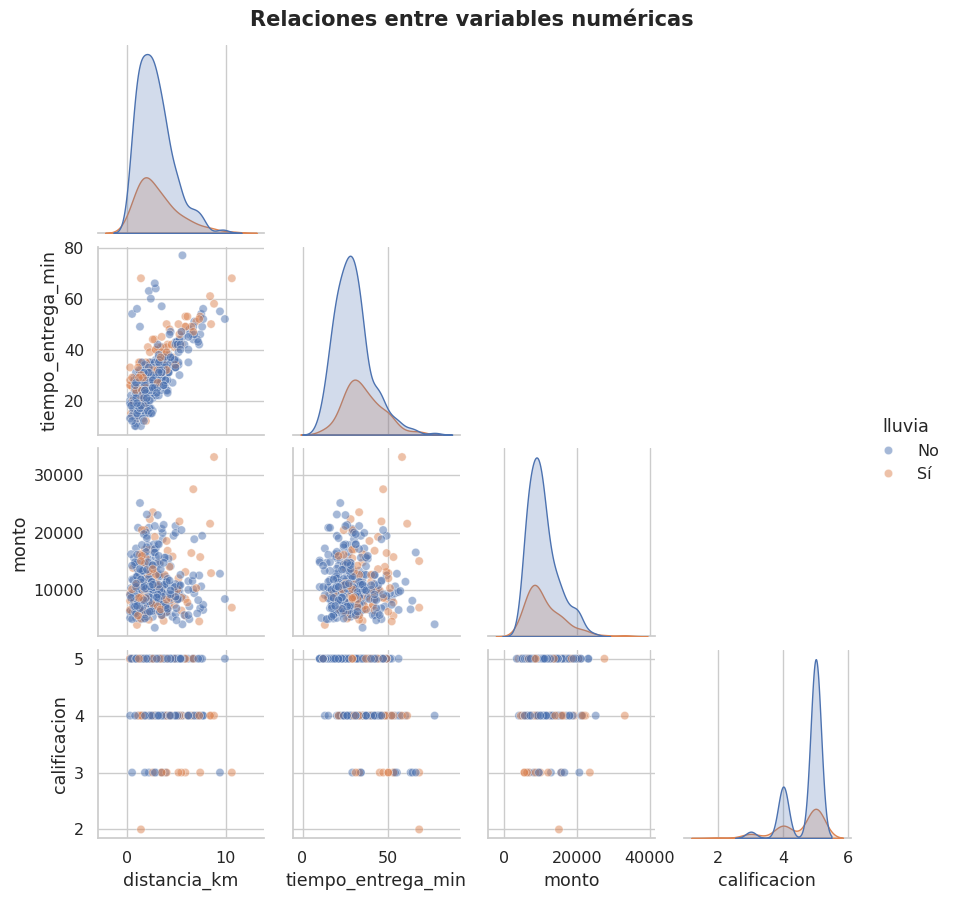

In [14]:
g = sns.pairplot(df, vars=['distancia_km', 'tiempo_entrega_min', 'monto', 'calificacion'], hue='lluvia', corner=True, plot_kws={'alpha': 0.5}, height=2.2)
g.figure.suptitle('Relaciones entre variables numéricas', y=1.02, fontweight='bold')
plt.show()

**Respuesta modelo:** se ve de un vistazo la relación creciente distancia → tiempo, la caída de la calificación cuando el tiempo sube y que `monto` solo se asocia con la propina (casi no se relaciona con tiempo, distancia ni calificación).

### ✏️ Ejercicio 4.2 (texto)
Mirando el heatmap y el pairplot, respondé en una celda de texto:
1. ¿Qué par de variables tiene la correlación más fuerte (en valor absoluto)?
2. ¿Qué variable parece **independiente** de todas las demás?
3. ¿Qué relación esperás que impacte en la calificación?

**Respuesta modelo:** (1) distancia–tiempo (r = 0,71). (2) `monto`: es casi independiente del tiempo, la distancia y la calificación (|r| < 0,1); solo se asocia con la propina (r = 0,51). (3) El **tiempo de entrega** se asocia negativamente con la calificación (r = -0,53): cuanto más demora, peor puntúa el cliente.

---
## 5️⃣ Seaborn + Matplotlib
Seaborn tiene **dos familias** de funciones:
- **Axes-level** (`histplot`, `boxplot`, `scatterplot`, `barplot`…): dibujan en *un* `ax` y aceptan `ax=`. Se combinan con `plt.subplots()`.
- **Figure-level** (`displot`, `catplot`, `lmplot`, `pairplot`): crean su propia figura y **no** aceptan `ax=`.

Regla práctica: si necesitás un layout propio, usá funciones axes-level con `ax=axes[i]`.

### ✏️ Ejercicio 5.1
Creá una figura de **1 fila × 2 columnas** (`figsize=(12, 4.5)`):
- **Izquierda:** `boxplot` de `tiempo_entrega_min` por `tipo_dia`.
- **Derecha:** `barplot` de la `calificacion` promedio por `zona` (con `ax.set_ylim(1, 5)`).

Títulos y ejes con unidades en cada `Axes`. Cerrá con `fig.tight_layout()` y guardá con `fig.savefig('delivery_layout.png', dpi=150, bbox_inches='tight')`.

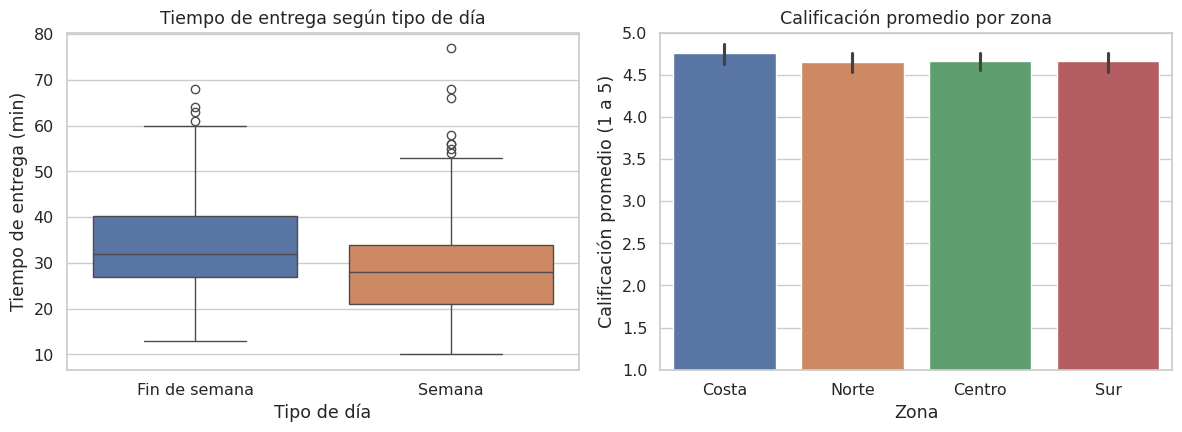

In [15]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4.5))

sns.boxplot(data=df, x='tipo_dia', y='tiempo_entrega_min', hue='tipo_dia', legend=False, ax=axes[0])
axes[0].set_title('Tiempo de entrega según tipo de día')
axes[0].set_xlabel('Tipo de día')
axes[0].set_ylabel('Tiempo de entrega (min)')

sns.barplot(data=df, x='zona', y='calificacion', hue='zona', legend=False, ax=axes[1])
axes[1].set_title('Calificación promedio por zona')
axes[1].set_xlabel('Zona')
axes[1].set_ylabel('Calificación promedio (1 a 5)')
axes[1].set_ylim(1, 5)

fig.tight_layout()
fig.savefig('delivery_layout.png', dpi=150, bbox_inches='tight')
plt.show()

**Respuesta modelo:** los fines de semana tienen medianas algo más altas; las calificaciones promedio por zona son muy parecidas, con barras de error que se solapan: no hay diferencias claras entre zonas.

### 🎯 Ejercicio 5.2 (bonus)
Con la función *figure-level* **`sns.displot`**, graficá el histograma de `tiempo_entrega_min` en **tres paneles** (uno por `franja`) usando `col='franja'` y `kde=True`.

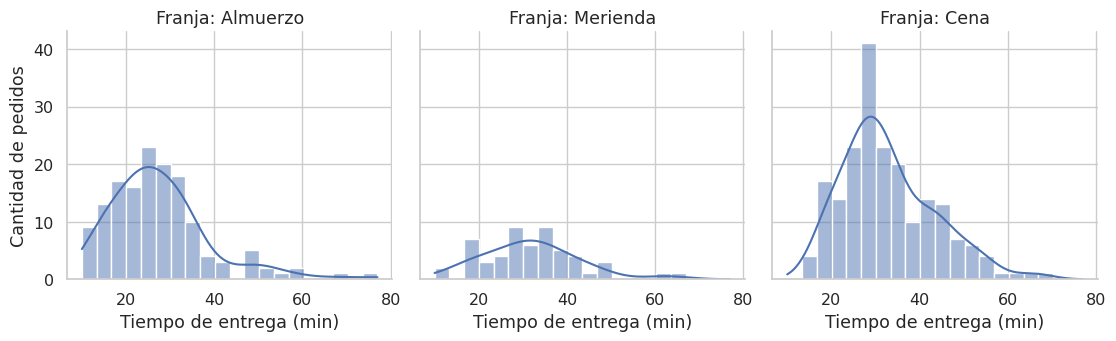

In [16]:
g = sns.displot(data=df, x='tiempo_entrega_min', col='franja', col_order=['Almuerzo', 'Merienda', 'Cena'], kde=True, bins=20, height=3.6, aspect=1.05)
g.set_axis_labels('Tiempo de entrega (min)', 'Cantidad de pedidos')
g.set_titles('Franja: {col_name}')
plt.show()

**Respuesta modelo:** la **cena** está desplazada a la derecha (mediana 31 min vs 26 en el almuerzo): es la franja más lenta, probablemente por mayor demanda.

---
## 6️⃣ Reto final: contá la historia 📖
**Pregunta de negocio:** *¿qué hace que un pedido demore y cómo impacta en la calificación del cliente?*

Armá **3 gráficos** (idealmente en una figura 1×3) que respondan la pregunta y escribí **3 líneas de conclusión** por gráfico. Criterios: estilo único, títulos, ejes con unidades, leyendas y **al menos un boxplot/violinplot y un scatter**.

> 💡 Pista: podés crear tramos con `pd.cut(df['tiempo_entrega_min'], bins=[0, 25, 35, 45, 200], labels=[...])`.

### ✏️ Tu reto

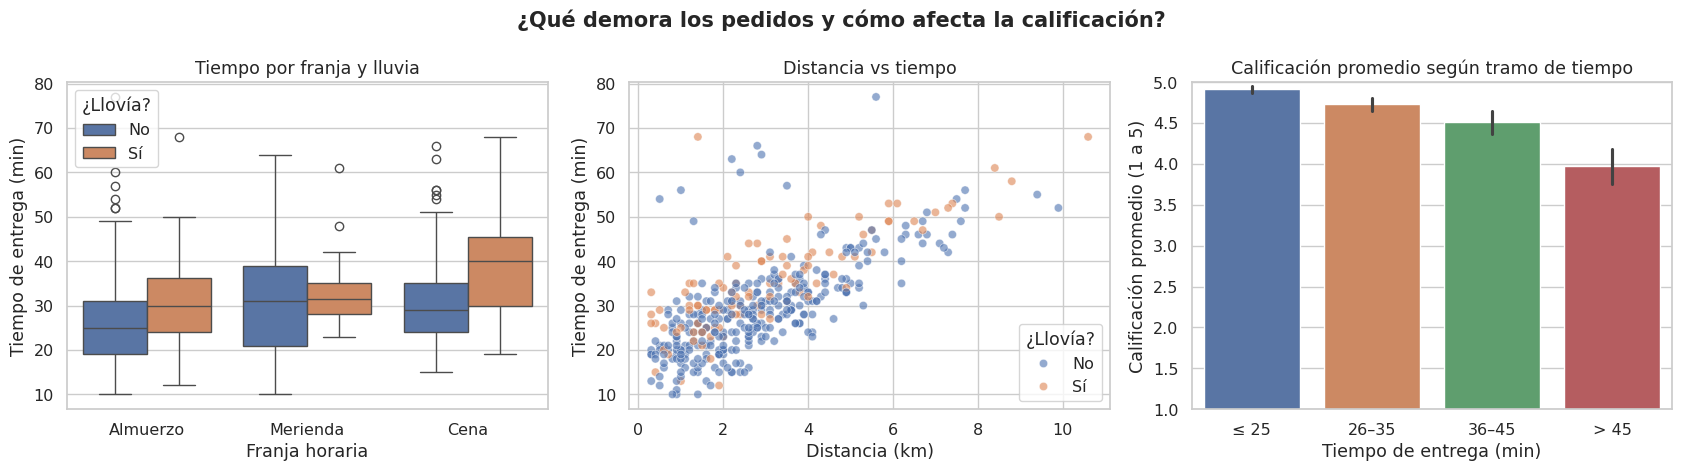

In [17]:
df['tramo_tiempo'] = pd.cut(df['tiempo_entrega_min'], bins=[0, 25, 35, 45, 200], labels=['≤ 25', '26–35', '36–45', '> 45'])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

sns.boxplot(data=df, x='franja', y='tiempo_entrega_min', hue='lluvia', order=['Almuerzo', 'Merienda', 'Cena'], ax=axes[0])
axes[0].set_title('Tiempo por franja y lluvia')
axes[0].set_xlabel('Franja horaria'); axes[0].set_ylabel('Tiempo de entrega (min)')
axes[0].legend(title='¿Llovía?')

sns.scatterplot(data=df, x='distancia_km', y='tiempo_entrega_min', hue='lluvia', alpha=0.6, ax=axes[1])
axes[1].set_title('Distancia vs tiempo')
axes[1].set_xlabel('Distancia (km)'); axes[1].set_ylabel('Tiempo de entrega (min)')
axes[1].legend(title='¿Llovía?')

sns.barplot(data=df, x='tramo_tiempo', y='calificacion', hue='tramo_tiempo', dodge=False, legend=False, ax=axes[2])
axes[2].set_title('Calificación promedio según tramo de tiempo')
axes[2].set_xlabel('Tiempo de entrega (min)'); axes[2].set_ylabel('Calificación promedio (1 a 5)')
axes[2].set_ylim(1, 5)

fig.suptitle('¿Qué demora los pedidos y cómo afecta la calificación?', fontsize=15, fontweight='bold')
fig.tight_layout()
plt.show()

**Conclusiones modelo:**
1. **Qué demora un pedido:** la **distancia** (≈ 4 min por km) es el factor principal; la **lluvia** suma ≈ 5 min fijos y la **cena** es la franja más lenta (31 vs 26 min de mediana).
2. **Anomalías:** hay 12 pedidos con demoras excepcionales que no se explican por distancia ni clima: conviene investigarlos como incidentes.
3. **Impacto en la calificación:** a mayor tiempo, menor puntaje (r = -0,53): la calificación media baja de 4,9 en entregas de hasta 25 min a 4,0 en las de más de 45 min.

## ✅ Autoevaluación
- [ ] Usé `sns.set_theme()` una sola vez al inicio
- [ ] Todos mis gráficos tienen título y ejes con unidades
- [ ] Leyenda en gráficos con `hue`
- [ ] Miré distribuciones y outliers **antes** de interpretar correlaciones
- [ ] Cada gráfico tiene una conclusión escrita